<a href="https://colab.research.google.com/github/IvanZinchenko3214/dap-2024/blob/main/les07/rep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Numpy version: 2.4.6
Pandas version: 2.2.3
Matplotlib version: 3.10.0


In [8]:
url = "https://raw.githubusercontent.com/Nikita-Puzyrev/dap-2024/main/les07/data/titanic.csv"
df = pd.read_csv(url, index_col='PassengerId')

In [9]:
print("Первые 7 строк набора данных:")
display(df.head(7))

Первые 7 строк набора данных:


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [10]:
df.drop(['Name', 'Ticket', 'Cabin', 'Embarked'], axis=1, inplace=True)

In [11]:
df['male'] = df['Sex'].apply(lambda x: 1 if x == 'male' else 0)
df['female'] = df['Sex'].apply(lambda x: 1 if x == 'female' else 0)
df.drop('Sex', axis=1, inplace=True)

In [12]:
df.dropna(inplace=True)

In [13]:
scaler = MinMaxScaler()
df['Fare'] = scaler.fit_transform(df[['Fare']])

In [14]:
fare_survived = df[df['Survived'] == 1]['Fare'].mean()
fare_died = df[df['Survived'] == 0]['Fare'].mean()
fare_diff = fare_survived - fare_died
print(f"Средний Fare выживших: {fare_survived:.4f}")
print(f"Средний Fare погибших: {fare_died:.4f}")
print(f"Разница средних значений Fare: {fare_diff:.4f}")

Средний Fare выживших: 0.1012
Средний Fare погибших: 0.0448
Разница средних значений Fare: 0.0564


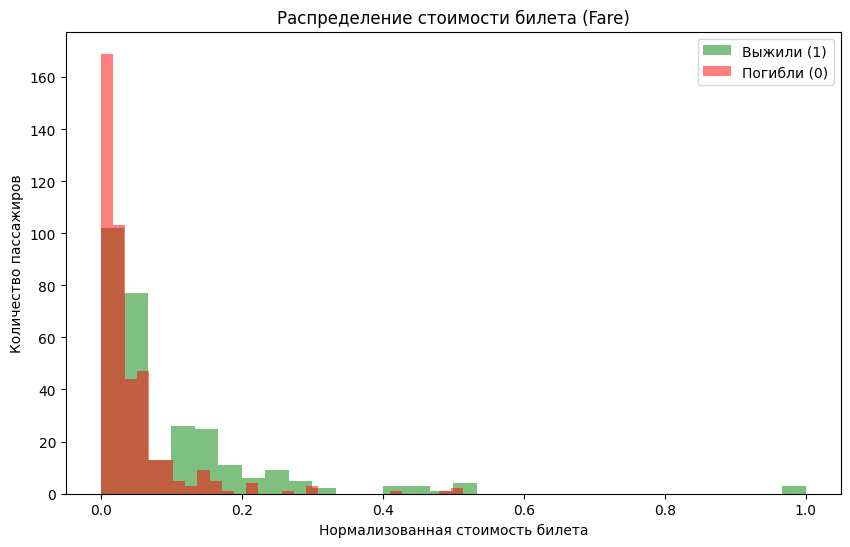

In [15]:
plt.figure(figsize=(10, 6))
plt.hist(df[df['Survived'] == 1]['Fare'], bins=30, alpha=0.5, color='green', label='Выжили (1)')
plt.hist(df[df['Survived'] == 0]['Fare'], bins=30, alpha=0.5, color='red', label='Погибли (0)')
plt.title('Распределение стоимости билета (Fare)')
plt.xlabel('Нормализованная стоимость билета')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.show()

In [16]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [18]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [19]:
y_pred = model.predict(X_test)

In [20]:
cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок:")
print(cm)
# Для наглядности можно вывести в виде DataFrame
print(pd.DataFrame(cm, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1']))

Матрица ошибок:
[[91 16]
 [23 49]]
          Predicted 0  Predicted 1
Actual 0           91           16
Actual 1           23           49


In [21]:
acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy (Точность модели): {acc:.4f} ({acc*100:.2f}%)")


Accuracy (Точность модели): 0.7821 (78.21%)


In [22]:
print("\n--- Вывод ---")
print(f"Модель случайного леса (Random Forest) показала точность (accuracy) около {acc*100:.2f}%.")
print("Это означает, что модель правильно определяет судьбу пассажира примерно в 8 из 10 случаев.")
print("Анализ гистограмм показал, что пассажиры, заплатившие за билет больше (высокие значения Fare),")
print("имели статистически больше шансов выжить (разница средних Fare положительная).")
print("Матрица ошибок позволяет увидеть, какие именно классы модель путает (ложноположительные и ложноотрицательные срабатывания).")


--- Вывод ---
Модель случайного леса (Random Forest) показала точность (accuracy) около 78.21%.
Это означает, что модель правильно определяет судьбу пассажира примерно в 8 из 10 случаев.
Анализ гистограмм показал, что пассажиры, заплатившие за билет больше (высокие значения Fare),
имели статистически больше шансов выжить (разница средних Fare положительная).
Матрица ошибок позволяет увидеть, какие именно классы модель путает (ложноположительные и ложноотрицательные срабатывания).
